# 03 · The dual pool on libfabric vs libibverbs, and the blob channel

The dual pool on libfabric (verbs MSG, verbs;ofi_rxm RDM, mixed) against the native libibverbs pool, same harness; the credit-window bound; FabricBlobChannel vs TcpBlobChannel.

**README sections covered:** [4. The dual pool on libfabric](../docs/explained/04-dual-pool.md), [5. FabricBlobChannel: credits and one-sided writes](../docs/explained/05-blob-channel.md)

Figures are written to `docs/figures/` (model figures: arithmetic, proofs and repo results) and `docs/figures/<MODE>/` (measured on the machine that ran the notebook).

In [1]:
MODE = "local"            # "local": smoke runs on this machine (tcp / tcp;ofi_rxm / shm providers)
                          # "cluster": this host is the client, the server runs on PEER over ssh
PEER = "server1"         # ssh host for the server side (cluster mode)
PEER_IP = "192.168.1.242" # server address on the RDMA netdev; default taken from benchmark_dual_qp_remote.py, check it
REMOTE_REPO = None        # repo path on PEER if it differs from this host
DOMAIN = "rxe0"           # RDMA device / libfabric domain on both nodes
SV_GID_INDEX = None       # set if the auto-picked GID (first IPv4-mapped) is wrong, e.g. "1"
HOT_CPU = None            # pin the hot loop (cluster: pick a core away from the NIC IRQs)
COLD_CPU = None           # pin the cold stream thread
ITERS = None              # None: 2000 local, 20000 cluster
RESULTS_SUBDIR = "fabric"


In [2]:
import os, sys, json, socket, subprocess, time
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "middleware").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
HOST = socket.gethostname()
STAMP = time.strftime("%Y%m%dT%H%M%SZ", time.gmtime())
RESULTS = (ROOT / "benchmarks" / "results" / RESULTS_SUBDIR) if MODE == "cluster" else Path("/tmp/scuffed-local") / RESULTS_SUBDIR
RESULTS.mkdir(parents=True, exist_ok=True)
FIGDIR = ROOT / "docs" / "figures"
(FIGDIR / MODE).mkdir(parents=True, exist_ok=True)

import matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 170, "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "legend.fontsize": 7.5, "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "lines.linewidth": 1.4,
    "lines.markersize": 4, "figure.constrained_layout.use": False})
C = {"hot": "#f97316", "cold": "#38bdf8", "spill": "#a78bfa", "ok": "#34d399", "bad": "#f43f5e",
     "gold": "#facc15", "ink": "#1f2937", "muted": "#94a3b8"}

def fig(name, model=False, caption=None, f=None):
    """Save the current figure as PNG + PDF and show it.
    model=True: arithmetic or repo results, same on every machine -> docs/figures/<name>
    model=False: measured on this machine -> docs/figures/<MODE>/<name>"""
    f = f or plt.gcf()
    d = FIGDIR if model else FIGDIR / MODE
    f.tight_layout()
    for ext in ("png", "pdf"):
        f.savefig(d / f"{name}.{ext}", bbox_inches="tight")
    print(f"figure -> {d.relative_to(ROOT)}/{name}.png" + (f"  |  {caption}" if caption else ""))
    plt.show()

def save(name, obj):
    p = RESULTS / f"{HOST}_{name}.json"
    obj = {"host": HOST, "utc": STAMP, "mode": MODE, **obj}
    p.write_text(json.dumps(obj, indent=2, default=str))
    print("wrote", p)
    return p

def sh(cmd, check=True):
    print("$", cmd)
    r = subprocess.run(cmd, shell=True, text=True, capture_output=True, cwd=ROOT)
    print(r.stdout[-4000:], r.stderr[-2000:])
    if check and r.returncode:
        raise RuntimeError(f"{cmd} -> {r.returncode}")
    return r
print("repo:", ROOT, "| host:", HOST, "| mode:", MODE, "| results ->", RESULTS, "| figures ->", FIGDIR)

repo: /home/claude/scuffedrdma | host: vm | mode: local | results -> /tmp/scuffed-local/fabric | figures -> /home/claude/scuffedrdma/docs/figures


## Math: one endpoint per class, and a credit window that never blocks the link

**Section 4, the dual pool.** The pool opens one endpoint per traffic class, each with its own transmit queue and completion objects, so nothing bulk is ever in front of a hot message in its own queue (section 2's $W_{\text{FIFO}}$ becomes the per-packet residual). Separate completion queues matter for the same reason: a CQ is read in order, so with $k$ cold completions queued ahead of a hot one the poller pays $k \cdot c_{\text{poll}}$ before it sees it; with a dedicated hot CQ that cost is independent of $k$. libfabric adds choices verbs does not expose directly: an `FI_EP_MSG` endpoint (connected, maps onto an RC queue pair) or `FI_EP_RDM` (reliable, unconnected, through `ofi_rxm`), counters (`fi_cntr`, with `FI_SELECTIVE_COMPLETION`) instead of a CQ for the hot class, and a wait object (`fi_cq_sread`) instead of busy polling for the cold class. `sv_bench` is the same benchmark source linked against `libscuffedverbs`, which implements the same API on raw RC queue pairs, so any difference between the two is the library.

**Section 5, the blob channel.** `FabricBlobChannel` carries key-value blobs over the pool with credits: each side registers $N$ receive slots of $B$ bytes (defaults $N = 8$, $B = 4$ MiB); the sender writes a chunk into a free slot at the peer with `fi_writedata`, and the receiver returns the slot with an 8-byte credit write after copying it out. Three properties are proved in [docs/explained/05](../docs/explained/05-blob-channel.md): a slot is never overwritten before it is consumed (a three-state invariant per slot), a staging buffer is never reused before its write completes, and a blob is delivered exactly when all its byte intervals have arrived (the intervals are consecutive and disjoint, the transport is reliable). What the window costs in throughput follows from Little's law. With $R$ the credit round trip (wire + receiver copy + credit write), at most $N$ chunks are in flight, so throughput $X$ satisfies

$$
N \;\ge\; X \cdot \frac{R}{B} \qquad\Longrightarrow\qquad X \;\le\; \frac{N B}{R},
$$

and the link rate $C$ is reachable only if the window covers the bandwidth-delay product, $NB \ge C R$. The next cell plots that bound: with 32 MiB in flight the channel is window-limited only when a credit takes longer than about 27 ms to come back on 10 Gb/s (2.7 ms on 100 Gb/s), far above a real credit round trip. So in E6, if `FabricBlobChannel` is slower than `TcpBlobChannel`, the cause is not the window.

In [3]:
from benchmarks.fabric import runner
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
CLUSTER = MODE == "cluster"
N = ITERS or (20000 if CLUSTER else 2000)
W = max(100, N // 20)
PAIR = dict(peer=PEER, peer_ip=PEER_IP, remote_repo=REMOTE_REPO) if CLUSTER else {}
ENV = {"SV_GID_INDEX": str(SV_GID_INDEX)} if SV_GID_INDEX is not None else {}
STACKS = runner.stacks(MODE)
if CLUSTER:
    for st in STACKS:
        if st["tool"] == "sf_bench":
            st["args"] += ["-d", DOMAIN]
        else:
            ENV.setdefault("SV_IB_PORT", "1")
PIN = (["--hot-cpu", str(HOT_CPU)] if HOT_CPU is not None else []) + (["--cold-cpu", str(COLD_CPU)] if COLD_CPU is not None else [])
print(runner.build(remote=PEER if CLUSTER else None, remote_repo=REMOTE_REPO))
for st in STACKS: print(st["label"], st["tool"], st["args"])

{'sf_bench': 'ok', 'sv_bench': 'ok'}
libfabric tcp MSG (local smoke) sf_bench ['-p', 'tcp', '-t', 'msg']
libfabric tcp;ofi_rxm RDM (local smoke) sf_bench ['-p', 'tcp;ofi_rxm', '-t', 'rdm']
libfabric shm RDM (local smoke) sf_bench ['-p', 'shm', '-t', 'rdm']


## 0. The credit window bound (model figure)

 10 Gb/s link is window-limited when the credit RTT exceeds 26.8 ms
 25 Gb/s link is window-limited when the credit RTT exceeds 10.7 ms
100 Gb/s link is window-limited when the credit RTT exceeds 2.7 ms


figure -> docs/figures/05_credit_window.png  |  arithmetic from the defaults


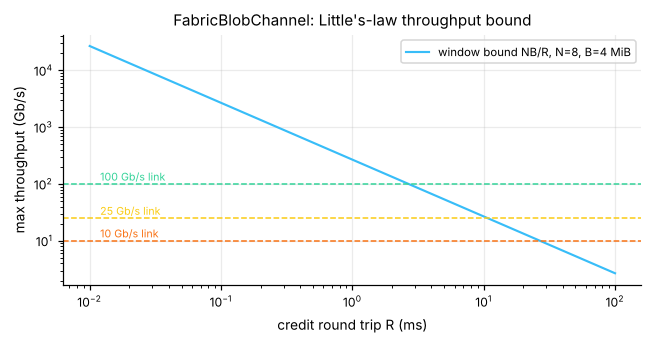

In [4]:
import numpy as np
Nslots, Bslot = 8, 4 << 20
R = np.logspace(-5, -1, 200)                    # credit round trip, 10 us .. 100 ms
X = Nslots * Bslot / R                           # bytes per second
figm, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(R * 1e3, X * 8 / 1e9, color=C["cold"], label=f"window bound NB/R, N={Nslots}, B={Bslot >> 20} MiB")
for rate, col in ((10, C["hot"]), (25, C["gold"]), (100, C["ok"])):
    ax.axhline(rate, color=col, ls="--", lw=1); ax.text(R[0] * 1e3 * 1.2, rate * 1.15, f"{rate} Gb/s link", color=col, fontsize=7)
    print(f"{rate:>3} Gb/s link is window-limited when the credit RTT exceeds {Nslots * Bslot * 8 / (rate * 1e9) * 1e3:.1f} ms")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("credit round trip R (ms)"); ax.set_ylabel("max throughput (Gb/s)")
ax.set_title("FabricBlobChannel: Little's-law throughput bound"); ax.legend()
fig("05_credit_window", model=True, caption="arithmetic from the defaults")

## 1. Hot-path latency: libibverbs vs libfabric verbs MSG vs verbs;ofi_rxm RDM

In [5]:
SIZES = "8,64,256,1024,4096,16384,65536" if CLUSTER else "64,4096,65536"
raw, lat = [], []
for st in STACKS:
    d = runner.try_pair(st["tool"], st["args"] + ["-m", "sig", "-M", "cq", "-n", str(N), "-w", str(W), "-S", SIZES, "--perf"], env=ENV, **PAIR)
    raw.append(d); lat += runner.rows_sig(d, st["label"])
lat = pd.DataFrame(lat); lat

,label,mech,size,n,mean_us,min_us,p50_us,p90_us,p99_us,p999_us,max_us,metric
0,libfabric tcp MSG (local smoke),cq,64,2000,6.6562,4.8385,6.2265,7.0251,19.5951,39.3144,209.7145,one_way_us_rtt_over_2
1,libfabric tcp MSG (local smoke),cq,4096,2000,13.7164,6.2295,12.9868,15.4133,33.7772,104.4729,1817.6340,one_way_us_rtt_over_2
2,libfabric tcp MSG (local smoke),cq,65536,2000,53.8739,41.6140,50.4805,65.9352,98.3869,190.7501,466.2375,one_way_us_rtt_over_2
3,libfabric tcp;ofi_rxm RDM (local smoke),cq,64,2000,14.9268,9.9340,13.7267,16.9372,41.5545,65.5772,88.9975,one_way_us_rtt_over_2
4,libfabric tcp;ofi_rxm RDM (local smoke),cq,4096,2000,18.9788,12.3670,17.2075,22.7158,46.2314,102.3336,196.4070,one_way_us_rtt_over_2
5,libfabric tcp;ofi_rxm RDM (local smoke),cq,65536,2000,60.6387,41.8925,55.7510,74.4262,118.1181,299.3661,1529.4705,one_way_us_rtt_over_2
6,libfabric shm RDM (local smoke),cq,64,2000,1.7516,1.1735,1.6150,1.8965,4.4605,18.5677,48.5060,one_way_us_rtt_over_2
7,libfabric shm RDM (local smoke),cq,4096,2000,3.8812,2.9395,3.5715,4.0641,7.3231,54.1203,80.8745,one_way_us_rtt_over_2
8,libfabric shm RDM (local smoke),cq,65536,2000,8.7775,6.4220,7.8882,9.6019,26.4483,62.8131,105.7255,one_way_us_rtt_over_2


## 2. Cold-path bandwidth

In [6]:
BW_SIZES = "4K,64K,256K,1M,4M,16M" if CLUSTER else "64K,1M"
bw = []
for st in STACKS:
    for wait in (False, True):
        a = st["args"] + ["-m", "bw", "-n", str(max(200, N // 20)), "-S", BW_SIZES, "-W", "16"] + (["--cold-wait"] if wait else [])
        d = runner.try_pair(st["tool"], a, env=ENV, **PAIR); raw.append(d)
        for r in d.get("results", []):
            bw.append({"label": st["label"], "cold_wait": wait, **r})
        if "error" in d: bw.append({"label": st["label"], "cold_wait": wait, "error": d["error"][:200]})
bw = pd.DataFrame(bw); bw

,label,cold_wait,size,iters,seconds,MBps,Gbps
0,libfabric tcp MSG (local smoke),False,65536,200,0.008430,1554.742,12.4379
1,libfabric tcp MSG (local smoke),False,1048576,200,0.123814,1693.792,13.5503
2,libfabric tcp MSG (local smoke),True,65536,200,0.007341,1785.577,14.2846
3,libfabric tcp MSG (local smoke),True,1048576,200,0.119585,1753.692,14.0295
4,libfabric tcp;ofi_rxm RDM (local smoke),False,65536,200,0.043775,299.425,2.3954
5,libfabric tcp;ofi_rxm RDM (local smoke),False,1048576,200,0.120428,1741.413,13.9313
6,libfabric tcp;ofi_rxm RDM (local smoke),True,65536,200,0.046633,281.073,2.2486
7,libfabric tcp;ofi_rxm RDM (local smoke),True,1048576,200,0.072585,2889.222,23.1138
8,libfabric shm RDM (local smoke),False,65536,200,0.005425,2416.132,19.3291
9,libfabric shm RDM (local smoke),False,1048576,200,0.079921,2624.027,20.9922


figure -> docs/figures/local/04_dualpool_latency_bw.png  |  E1, E2


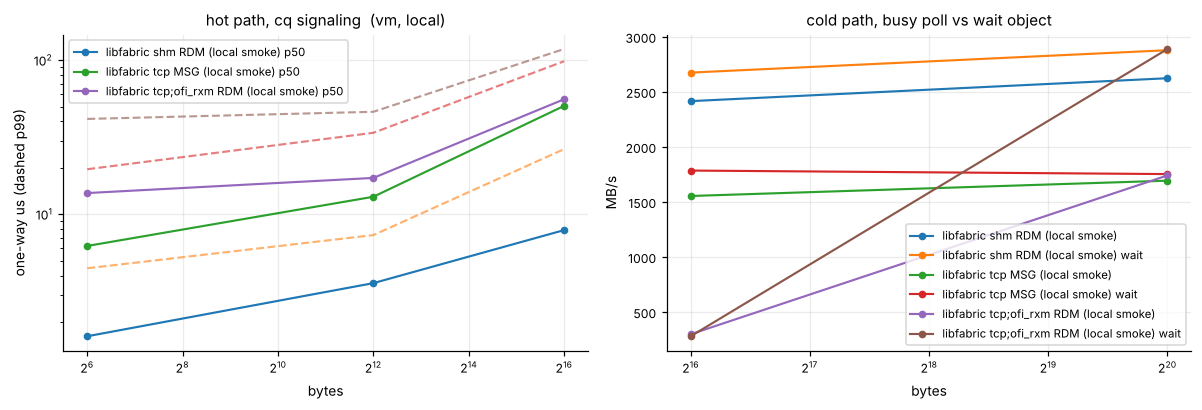

In [7]:
figx, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ok = lat.dropna(subset=["p50_us"]) if "p50_us" in lat else lat
for lab, g in ok.groupby("label"):
    ax[0].plot(g["size"], g["p50_us"], marker="o", label=f"{lab} p50"); ax[0].plot(g["size"], g["p99_us"], ls="--", alpha=.6)
ax[0].set_xscale("log", base=2); ax[0].set_yscale("log"); ax[0].set_xlabel("bytes"); ax[0].set_ylabel("one-way us (dashed p99)"); ax[0].legend()
ax[0].set_title(f"hot path, cq signaling  ({HOST}, {MODE})")
okb = bw.dropna(subset=["MBps"]) if "MBps" in bw else bw
for (lab, wait), g in okb.groupby(["label", "cold_wait"]):
    ax[1].plot(g["size"], g["MBps"], marker="o", label=f"{lab}{' wait' if wait else ''}")
ax[1].set_xscale("log", base=2); ax[1].set_xlabel("bytes"); ax[1].set_ylabel("MB/s"); ax[1].legend(); ax[1].set_title("cold path, busy poll vs wait object")
fig("04_dualpool_latency_bw", caption="E1, E2")

## 3. libfabric configuration matrix (endpoint types, counters, wait objects) under mixed traffic

In [8]:
prov = "verbs" if CLUSTER else "tcp"
rdm_prov = "verbs;ofi_rxm" if CLUSTER else "tcp;ofi_rxm"
dom = ["-d", DOMAIN] if CLUSTER else []
MATRIX = {
    "MSG/MSG (RC/RC)": ["-p", prov, "-t", "msg"],
    "RDM/RDM": ["-p", rdm_prov, "-t", "rdm"],
    "hot RDM + cold MSG": ["--hot-prov", rdm_prov, "--hot-ep", "rdm", "--cold-prov", prov, "--cold-ep", "msg"],
    "MSG/MSG, hot fi_cntr": ["-p", prov, "-t", "msg", "--hot-cntr"],
    "MSG/MSG, cold wait obj": ["-p", prov, "-t", "msg", "--cold-wait"],
    "MSG single EP (baseline)": ["-p", prov, "-t", "msg", "-s"],
}
mat = []
for lab, a in MATRIX.items():
    for cold in (False, True):
        args = a + dom + ["-m", "hol", "-n", str(N), "-w", str(W), "-W", "8"] + PIN + ([] if cold else ["--no-cold"])
        d = runner.try_pair("sf_bench", args, env=ENV, **PAIR); raw.append(d)
        mat.append(runner.rows_hol(d, lab))
mat = pd.DataFrame(mat); mat

,label,single_ep,cold_on,cold_size,hot_size,hot_p50_us,hot_p90_us,hot_p99_us,hot_p999_us,hot_max_us,cold_MBps,n
0,MSG/MSG (RC/RC),0,0,1048576,64,20.3695,24.4518,53.6289,121.2387,146.066,0.000,2000
1,MSG/MSG (RC/RC),0,1,1048576,64,13.0635,19.0349,126.7105,5965.0075,6535.123,666.548,2000
2,RDM/RDM,0,0,1048576,64,14.7505,19.6652,55.3143,107.6195,173.392,0.000,2000
3,RDM/RDM,0,1,1048576,64,17.5785,23.9468,1633.5463,4100.8074,6347.567,611.119,2000
4,hot RDM + cold MSG,0,0,1048576,64,13.8225,18.1412,51.4371,119.7466,330.763,0.000,2000
5,hot RDM + cold MSG,0,1,1048576,64,24.6255,34.6272,4087.2965,4196.4568,4406.388,653.840,2000
6,"MSG/MSG, hot fi_cntr",0,0,1048576,64,18.3770,23.9844,76.1852,122.8322,366.607,0.000,2000
7,"MSG/MSG, hot fi_cntr",0,1,1048576,64,14.9065,20.1814,66.2608,5646.0888,5764.382,594.205,2000
8,"MSG/MSG, cold wait obj",0,0,1048576,64,22.0315,26.7100,66.9591,185.2127,406.858,0.000,2000
9,"MSG/MSG, cold wait obj",0,1,1048576,64,13.7435,23.7230,224.1267,4341.4659,5241.290,695.107,2000


figure -> docs/figures/local/04_dualpool_matrix.png  |  E3, E4: which endpoint/completion combination keeps hot p99 flat under load


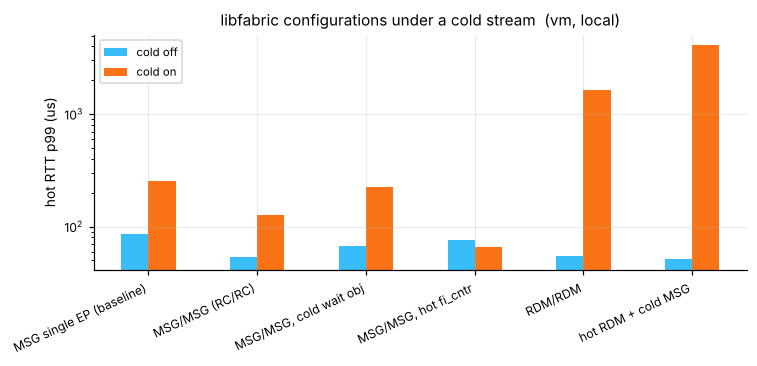

In [9]:
okm = mat.dropna(subset=["hot_p99_us"]) if "hot_p99_us" in mat else mat
if len(okm):
    piv = okm.pivot_table(index="label", columns="cold_on", values="hot_p99_us")
    piv.columns = ["cold off", "cold on"] if list(piv.columns) == [0, 1] else piv.columns
    figm2, ax = plt.subplots(figsize=(7, 3.4))
    piv.plot.bar(ax=ax, color=[C["cold"], C["hot"]][: len(piv.columns)]); ax.set_yscale("log"); ax.set_ylabel("hot RTT p99 (us)")
    ax.set_title(f"libfabric configurations under a cold stream  ({HOST}, {MODE})"); ax.set_xlabel("")
    plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
    fig("04_dualpool_matrix", caption="E3, E4: which endpoint/completion combination keeps hot p99 flat under load")
else:
    print("no matrix rows completed")

## 4. Application level: FabricBlobChannel vs TcpBlobChannel

In [10]:
import threading, time as _t
from middleware.fabric.channel import TcpBlobChannel
from middleware.fabric.pool import FabricBlobChannel
BLOBS = [4096, 65536, 1 << 20, 8 << 20]
REPS = 50 if CLUSTER else 10
def blob_bench(make_pair, label):
    """One channel pair per blob size so a stalled size cannot poison the next one.
    A size that does not finish within the timeout is recorded with ok=False instead of hanging the notebook."""
    out = []
    for sz in BLOBS:
        a, b = make_pair()
        try:
            payload = os.urandom(sz)
            done, err = threading.Event(), {}
            def rx():
                try:
                    for _ in range(REPS): b.recv(timeout=20)
                    done.set()
                except Exception as e:
                    err["recv"] = repr(e)
            t = threading.Thread(target=rx, daemon=True); t.start()
            t0 = _t.perf_counter()
            import inspect
            skw = {"timeout": 20} if "timeout" in inspect.signature(a.send).parameters else {}
            try:
                for i in range(REPS): a.send(f"k{i}", payload, hot=sz <= 4096, **skw)
            except Exception as e:
                err["send"] = repr(e)
            ok = done.wait(30) and not err; dt = _t.perf_counter() - t0
            out.append({"label": label, "blob_bytes": sz, "ok": ok, "MBps": sz * REPS / dt / 1e6 if ok else float("nan"),
                        "ms_per_blob": dt / REPS * 1e3 if ok else float("nan"), "error": "; ".join(f"{k}: {v}" for k, v in err.items()) or ("timeout" if not ok else "")})
        finally:
            a.close(); b.close()
    return out
def pair(make_s, make_c):
    box = {}
    th = threading.Thread(target=lambda: box.setdefault("s", make_s())); th.start(); _t.sleep(0.3)
    c = make_c(); th.join(); return c, box["s"]
if CLUSTER:
    print("cluster: run benchmarks/fabric/blob_bench.py on both nodes (server on PEER) for cross-node numbers;"
          " in-process numbers below are loopback on this host only")
port = 31500 + os.getpid() % 300
app = blob_bench(lambda: pair(lambda: TcpBlobChannel.listen(port, "127.0.0.1"), lambda: TcpBlobChannel.connect("127.0.0.1", port)), "TcpBlobChannel loopback")
fp = "tcp" if not CLUSTER else "verbs"
app += blob_bench(lambda: pair(lambda: FabricBlobChannel.listen(port + 1, "127.0.0.1", provider=fp, ep_type="msg", nslots=4, slot_mb=4),
                               lambda: FabricBlobChannel.connect("127.0.0.1", port + 1, provider=fp, ep_type="msg", nslots=4, slot_mb=4)),
                  f"FabricBlobChannel {fp} MSG loopback")
app = pd.DataFrame(app)
if not app.ok.all():
    print("NOTE: some blob sizes did not complete:", app[~app.ok][["label", "blob_bytes", "error"]].to_dict("records"))
    print("      multi-chunk blobs (larger than one slot) stall intermittently on the libfabric tcp provider loopback; see benchmarks/fabric/blob_multichunk_check.py")
app

NOTE: some blob sizes did not complete: [{'label': 'FabricBlobChannel tcp MSG loopback', 'blob_bytes': 8388608, 'error': "recv: TimeoutError('no blob before timeout')"}]
      multi-chunk blobs (larger than one slot) stall intermittently on the libfabric tcp provider loopback; see benchmarks/fabric/blob_multichunk_check.py


,label,blob_bytes,ok,MBps,ms_per_blob,error
0,TcpBlobChannel loopback,4096,True,30.327150,0.135060,
1,TcpBlobChannel loopback,65536,True,504.049796,0.130019,
2,TcpBlobChannel loopback,1048576,True,1083.080005,0.968143,
3,TcpBlobChannel loopback,8388608,True,698.530233,12.008940,
4,FabricBlobChannel tcp MSG loopback,4096,True,13.934926,0.293938,
5,FabricBlobChannel tcp MSG loopback,65536,True,186.524663,0.351353,
6,FabricBlobChannel tcp MSG loopback,1048576,True,890.244578,1.177852,
7,FabricBlobChannel tcp MSG loopback,8388608,False,NaN,NaN,recv: TimeoutError('no blob before timeout')


figure -> docs/figures/local/05_blob_channel.png  |  E6 (loopback here; cross-node from benchmarks/fabric/blob_bench.py)


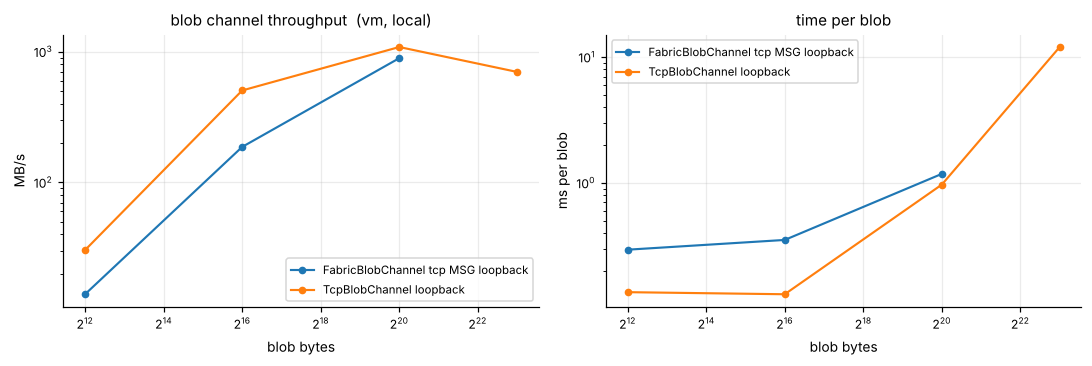

wrote /tmp/scuffed-local/fabric/vm_libfabric_vs_libibverbs.json


PosixPath('/tmp/scuffed-local/fabric/vm_libfabric_vs_libibverbs.json')

In [11]:
figb, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for lab, g in app[app.ok].groupby("label"):
    ax[0].plot(g.blob_bytes, g.MBps, marker="o", label=lab); ax[1].plot(g.blob_bytes, g.ms_per_blob, marker="o", label=lab)
for a_, yl in zip(ax, ("MB/s", "ms per blob")):
    a_.set_xscale("log", base=2); a_.set_yscale("log"); a_.set_xlabel("blob bytes"); a_.set_ylabel(yl); a_.legend()
ax[0].set_title(f"blob channel throughput  ({HOST}, {MODE})"); ax[1].set_title("time per blob")
fig("05_blob_channel", caption="E6 (loopback here; cross-node from benchmarks/fabric/blob_bench.py)")
save("libfabric_vs_libibverbs", {"latency": lat.to_dict("records"), "bandwidth": bw.to_dict("records"),
                                    "matrix": mat.to_dict("records"), "blob": app.to_dict("records"), "raw": raw})

In [12]:
# LaTeX table fragment for the update (cluster runs only)
if CLUSTER:
    t = ok.pivot_table(index="size", columns="label", values="p50_us")
    tex = t.to_latex(float_format="%.2f", caption="Hot-path one-way latency p50 ($\\mu$s), cq signaling", label="tab:fabric-lat")
    (RESULTS / f"{HOST}_latency_table.tex").write_text(tex); print(tex)

## 5. Telemetry export (what Prometheus scrapes from a worker)

In [13]:
from middleware import telemetry
print(telemetry.default().prometheus_text()[:1500])

# HELP scuffed_ops_total Completed operations per traffic class
# TYPE scuffed_ops_total counter
scuffed_ops_total{node="vm",class="cold"} 30
scuffed_ops_total{node="vm",class="hot"} 10
# HELP scuffed_bytes_total Bytes moved per traffic class
# TYPE scuffed_bytes_total counter
scuffed_bytes_total{node="vm",class="cold"} 95027200
scuffed_bytes_total{node="vm",class="hot"} 40960
# HELP scuffed_events_total QP error, reconnect, TCP fallback, timeout and retry events
# TYPE scuffed_events_total counter
scuffed_events_total{node="vm",class="cold",kind="qp_error"} 0
scuffed_events_total{node="vm",class="cold",kind="reconnect"} 0
scuffed_events_total{node="vm",class="cold",kind="retry"} 0
scuffed_events_total{node="vm",class="cold",kind="tcp_fallback"} 0
scuffed_events_total{node="vm",class="cold",kind="timeout"} 0
scuffed_events_total{node="vm",class="hot",kind="qp_error"} 0
scuffed_events_total{node="vm",class="hot",kind="reconnect"} 0
scuffed_events_total{node="vm",class="hot",kind="retry"